# IPL Score Prediction: how many runs will this innings make?

**The question:** you're watching a Twenty20 cricket match. After 10 of the 20 overs the batting side is 82 for 3. What will the final score be, and how much should you trust that guess? This notebook uses ball-by-ball records of **every Indian Premier League match since 2008** to answer, and to ask a more basic question first: has the game itself changed?

**How this notebook works.** Each section starts with a plain-English explanation, then the code, then a "how to read this" note.

1. The analogy
2. Setup
3. Audit the data (and a fatal error in the legacy notebook)
4. Hypotheses and why we chose each test
5. H1: has scoring changed over the years?
6. H2: does the toss or chasing matter?
7. H3: how many runs does a wicket cost?
8. H4: forecasting the final score, honestly
9. H5: do team and ground names help?
10. H6: how wide should the "likely range" be?
11. Takeaways
12. Limitations

**Run it:** `uv run jupyter lab ML/ipl-score-prediction/ipl_score_prediction.ipynb`, or *Run All* in any Jupyter. The data (about 7 MB) downloads itself on the first run, and the notebook takes about a minute.

## 1. 💡 The simple analogy

Think of a **road trip**. After driving for two hours you can guess your arrival time from your **average speed so far**, and that is exactly the cricket commentator's "current run rate" projection: *runs so far ÷ balls so far × 120 balls*.

But a smart driver adjusts for what they know:

- **The road ahead is not the road behind.** The last overs of a T20 innings are a sprint (batters swing hard), so the average speed so far *under*-predicts the finish.
- **Breakdowns matter.** A team that has lost many wickets is a car with a flat tyre: it can't speed up, however many overs remain.
- **The whole motorway changes over the years.** If speed limits keep rising, a forecast built on old traffic will be too slow.

We will build the forecast step by step, measure whether each ingredient (recent form, wickets, the ground, the team, the era) really helps, and check that we aren't fooling ourselves.

## 2. Setup

*What:* imports and named constants. *Why:* one place for numbers like the random seed keeps the notebook reproducible and avoids "magic numbers". With the seed fixed, every bootstrap and every model fit comes out the same each time you run it.

In [1]:
import csv
import urllib.request
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from statsmodels.stats.proportion import proportion_confint

DATA_URL = "https://cricsheet.org/downloads/ipl_csv2.zip"
DATA_PATH = Path("data/ipl_csv2.zip")
OUT_DIR = Path("outputs")
SEED = 42
N_BOOTSTRAP = 5_000
BALLS_IN_INNINGS = 120
CHECKPOINTS = [6, 10, 15, 18]  # overs completed when we make a forecast
FIRST_TEST_SEASON = 2018
TEAM_RENAMES = {
    "Delhi Daredevils": "Delhi Capitals",
    "Kings XI Punjab": "Punjab Kings",
    "Royal Challengers Bangalore": "Royal Challengers Bengaluru",
    "Rising Pune Supergiants": "Rising Pune Supergiant",
}
TEAL, ORANGE, NAVY, GREY = "#2a9d8f", "#e76f51", "#264653", "#b8bcc2"

sns.set_theme(style="whitegrid", context="notebook")
OUT_DIR.mkdir(exist_ok=True)

## 3. Audit the data first

*What:* download and inspect the data. *Why:* the legacy notebook's results were meaningless, and the reason was in the data. Here is what went wrong:

> **A fatal error in the legacy notebook.** It tried to predict a column called `total_runs`, treating it as "the match score". But in a *ball-by-ball* file, `total_runs` is the **runs scored from a single delivery** (0, 1, 2, 3, 4 or 6). So it was predicting how many runs the *next ball* would make, using columns such as `winner` and `result` that are only known **after** the match. It also computed "RMSE" as the square root of the *MAE* (not the RMSE), the train and test rows didn't line up, and it saved models with `pickle` (which can run arbitrary code when loaded). We rebuild the problem properly.

**The data source** is [Cricsheet](https://cricsheet.org), which publishes open ball-by-ball records for every IPL match (licensed under the Open Data Commons Attribution License; credit: Cricsheet.org). Each row is one delivery. We use the **first innings** of each match only (a first innings is a fair test: the batting side is not chasing a target, so we are predicting *how many runs they make*, not whether they win).

In [2]:
def load_cricsheet(path: Path = DATA_PATH) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Loads all IPL deliveries and match summaries, downloading them on first use.

    Args:
        path: Where to cache the Cricsheet zip archive.

    Returns:
        Ball-by-ball deliveries and a one-row-per-match summary table.

    Raises:
        ValueError: If no deliveries were found.
    """
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        urllib.request.urlretrieve(DATA_URL, path)
    columns = [
        "match_id",
        "start_date",
        "venue",
        "innings",
        "ball",
        "batting_team",
        "bowling_team",
        "runs_off_bat",
        "extras",
        "wides",
        "noballs",
        "wicket_type",
    ]
    with zipfile.ZipFile(path) as archive:
        with archive.open("all_matches.csv") as handle:
            deliveries = pd.read_csv(handle, usecols=columns)
        summaries = []
        for name in archive.namelist():
            if not name.endswith("_info.csv"):
                continue
            info: dict[str, str] = {}
            for line in archive.read(name).decode().splitlines():
                parts = next(csv.reader([line]))
                if len(parts) >= 3 and parts[0] == "info" and parts[1] not in info:
                    info[parts[1]] = parts[2]
            summaries.append(info)
    if deliveries.empty:
        raise ValueError("No deliveries found in the archive")
    matches = pd.DataFrame(summaries).reindex(
        columns=["match_id", "date", "toss_winner", "toss_decision", "winner"]
    )
    matches["match_id"] = matches["match_id"].astype(int)
    return deliveries, matches


deliveries, matches = load_cricsheet()
n_matches = deliveries["match_id"].nunique()
print(f"Deliveries: {len(deliveries):,}   Matches with deliveries: {n_matches:,}")
print(
    f"Innings numbers present: {sorted(deliveries['innings'].unique())} "
    "(3 and above are super overs, which we ignore)"
)
print(
    f"Matches in the summary table: {len(matches):,}; with a recorded winner: "
    f"{matches['winner'].notna().sum():,}"
)
deliveries.head(3)

Deliveries: 295,732   Matches with deliveries: 1,243
Innings numbers present: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)] (3 and above are super overs, which we ignore)
Matches in the summary table: 1,243; with a recorded winner: 1,218


,match_id,start_date,venue,innings,ball,batting_team,bowling_team,runs_off_bat,extras,wides,noballs,wicket_type
0,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.1,Sunrisers Hyderabad,Royal Challengers Bangalore,0,0,NaN,NaN,NaN
1,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.2,Sunrisers Hyderabad,Royal Challengers Bangalore,0,0,NaN,NaN,NaN
2,1082591,2017-04-05,"Rajiv Gandhi International Stadium, Uppal",1,0.3,Sunrisers Hyderabad,Royal Challengers Bangalore,4,0,NaN,NaN,NaN


**How to read this.** The archive holds about **296,000 deliveries from 1,243 matches**. Innings 1 and 2 are the two normal innings; innings 3 to 6 are **super overs** (tie-breakers) and are ignored. Some matches have no recorded winner (abandoned or tied), which matters for the toss analysis.

### Turning deliveries into forecasting "snapshots"

*What:* for every first innings we create one **snapshot at the end of each over** (overs 1 to 19), recording what a forecaster would know *at that moment*:

- `runs` and `wickets` so far, and `balls` bowled (**legal** balls only: wides and no-balls don't count);
- **recent form:** runs and wickets in the last 5 overs;
- the batting team, bowling team and ground (names tidied, because teams renamed themselves, e.g. Delhi Daredevils became Delhi Capitals);
- the **season**, and a `league_level`: the **average first-innings total of the previous two seasons**. This one needs care: it is something a forecaster genuinely knows *before* the season starts, so it carries no leakage.

The **target** is the innings' **final total** (including extras). Each snapshot only uses deliveries up to that over, so nothing from the future can leak in.

In [3]:
def build_snapshots(deliveries: pd.DataFrame) -> pd.DataFrame:
    """Builds one forecasting snapshot per match and completed over of the first innings.

    Args:
        deliveries: All IPL deliveries from :func:`load_cricsheet`.

    Returns:
        One row per (match, completed overs) with the state at that moment, the season
        (calendar year), team and ground names, and the final innings total as ``total``.
    """
    first = deliveries[deliveries["innings"] == 1].copy()
    first["over"] = first["ball"].astype(float).astype(int)
    first["runs"] = first["runs_off_bat"] + first["extras"]
    first["legal"] = (first["wides"].isna() & first["noballs"].isna()).astype(int)
    first["wicket"] = (
        first["wicket_type"].notna() & (first["wicket_type"] != "retired hurt")
    ).astype(int)
    per_over = first.groupby(["match_id", "over"]).agg(
        runs=("runs", "sum"), legal=("legal", "sum"), wickets=("wicket", "sum")
    )
    per_over = per_over.reset_index().sort_values(["match_id", "over"])
    grouped = per_over.groupby("match_id")
    per_over["cum_runs"] = grouped["runs"].cumsum()
    per_over["cum_wickets"] = grouped["wickets"].cumsum()
    per_over["cum_balls"] = grouped["legal"].cumsum()
    per_over["last5_runs"] = grouped["runs"].transform(lambda s: s.rolling(5, min_periods=1).sum())
    per_over["last5_wickets"] = grouped["wickets"].transform(
        lambda s: s.rolling(5, min_periods=1).sum()
    )
    per_over["overs_done"] = per_over["over"] + 1
    totals = first.groupby("match_id")["runs"].sum().rename("total")
    meta = first.groupby("match_id").agg(
        date=("start_date", "first"),
        venue=("venue", "first"),
        batting_team=("batting_team", "first"),
        bowling_team=("bowling_team", "first"),
    )
    snap = per_over.merge(meta, left_on="match_id", right_index=True).merge(
        totals, left_on="match_id", right_index=True
    )
    snap["season"] = pd.to_datetime(snap["date"]).dt.year
    for column in ("batting_team", "bowling_team"):
        snap[column] = snap[column].replace(TEAM_RENAMES)
    snap["ground"] = snap["venue"].str.split(",").str[0].str.strip()
    snap = snap[snap["overs_done"] <= 19].rename(
        columns={"cum_runs": "score", "cum_wickets": "wkts", "cum_balls": "balls"}
    )
    return snap.reset_index(drop=True)


snapshots = build_snapshots(deliveries)
match_totals = snapshots.groupby("match_id").agg(
    season=("season", "first"), total=("total", "first"), batting_team=("batting_team", "first")
)
season_means = match_totals.groupby("season")["total"].mean()
previous_two = {
    year: match_totals.loc[match_totals["season"].between(year - 2, year - 1), "total"].mean()
    for year in match_totals["season"].unique()
}
snapshots["league_level"] = snapshots["season"].map(previous_two)  # NaN for the first season
print(
    f"Snapshots: {len(snapshots):,} from {snapshots['match_id'].nunique():,} first innings "
    f"({snapshots['season'].min()} to {snapshots['season'].max()})"
)
print(
    f"Grounds: {snapshots['ground'].nunique()}, "
    f"batting teams: {snapshots['batting_team'].nunique()}"
)
print(
    f"First-innings total: mean {match_totals['total'].mean():.1f}, "
    f"median {match_totals['total'].median():.0f}, range {match_totals['total'].min()} to "
    f"{match_totals['total'].max()}"
)
snapshots[["match_id", "overs_done", "score", "wkts", "balls", "last5_runs", "total"]].head(4)

Snapshots: 23,434 from 1,243 first innings (2008 to 2026)
Grounds: 42, batting teams: 15
First-innings total: mean 168.6, median 168, range 25 to 287


,match_id,overs_done,score,wkts,balls,last5_runs,total
0,335982,1,3,0,6,3.0,222
1,335982,2,21,0,12,21.0,222
2,335982,3,27,0,18,27.0,222
3,335982,4,50,0,24,50.0,222


**How to read this.** We now have **23,434 snapshots from 1,243 first innings, 2008 to 2026**. The mean first-innings total is about **169 runs** (median 168), with a wide range (25 to 287: the smallest is an innings cut short by rain or a collapse). Note `balls` counts only legal deliveries, so after 10 overs it is 60 (or fewer if an over was cut short).

## 4. 🔬 Hypotheses and why we chose each test

Here are the questions, each with its null (H₀, "nothing special") and alternative (Hₐ), written **before** looking at any p-values:

| # | Question | H₀ | Hₐ | Method |
|---|---|---|---|---|
| H1 | Have first-innings totals changed over the seasons? | No monotonic trend | A trend exists | Mann-Kendall test and Theil-Sen slope on season averages; Mann-Whitney U, early vs recent era |
| H2 | Does winning the toss, or chasing, help win the match? | P(win) = 0.5 | P(win) ≠ 0.5 | Binomial test with Wilson CIs |
| H3 | At the same score, does losing wickets lower the final total? | Coefficient on wickets = 0 | The coefficient is negative | OLS with robust (HC3) standard errors |
| H4 | Does a model beat the "current run rate" forecast, and how does its error shrink during the innings? | MAE difference = 0 | The model has lower error | Rolling-origin evaluation by season; cluster bootstrap over matches |
| H5 | Do team and ground identity, or the recent league level, add anything? | MAE difference = 0 | They help | Same evaluation with each ingredient removed |
| H6 | Are our "likely range" intervals honest? | Coverage = 80% | Coverage differs | Intervals calibrated on earlier seasons, tested on the next |

**Why Mann-Kendall and Theil-Sen?** A straight-line regression is easily dragged by a few odd seasons. **Mann-Kendall** only uses the *order* of the values (does a later season tend to score more than an earlier one?; Kendall's τ runs from −1 to +1), and the **Theil-Sen slope** is the *median* of the slopes between every pair of seasons, so a few outliers can't move it. **Why robust (HC3) standard errors in H3?** Ordinary regression assumes the scatter around the line is the same everywhere; HC3 stays trustworthy when it isn't. **Why a cluster bootstrap in H4?** The 19 snapshots of one match are strongly correlated, so resampling single snapshots would make our intervals far too narrow; instead we resample **whole matches**.

## 5. H1: has scoring changed over the years?

*What:* the average first-innings total for each season, with a Mann-Kendall trend test and a Theil-Sen slope (95% CI), and a head-to-head comparison of the earlier seasons (2008 to 2022) with the recent ones (2023 onwards) using Mann-Whitney U and **Cliff's δ** (*P(a recent total is higher) − P(it is lower)*, from −1 to +1; |δ| about 0.15 small, 0.33 medium, 0.47 large).

Seasons: 2008 to 2026 (19 seasons)
Mann-Kendall: tau = +0.70, p = 6.5e-06
Theil-Sen slope: +1.91 runs per season (95% CI +1.26 to +2.59)
Mean first-innings total: 162.4 in 2008-2022 vs 188.5 in 2023+ (950 and 293 matches)
Mann-Whitney p = 1.2e-28, Cliff's delta = +0.43


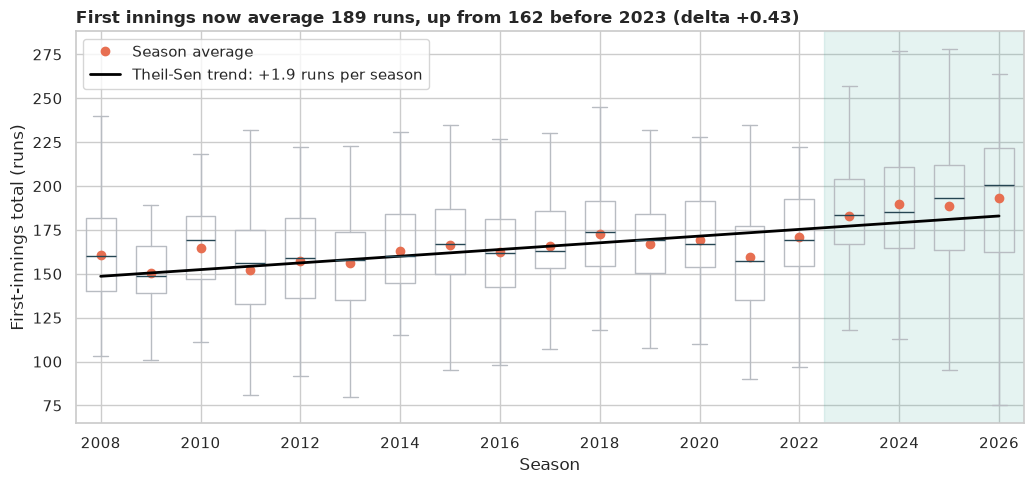

In [4]:
seasons = season_means.index.to_numpy()
tau = stats.kendalltau(seasons, season_means.to_numpy())
slope, intercept, slope_lo, slope_hi = stats.theilslopes(season_means.to_numpy(), seasons)
early = match_totals.loc[match_totals["season"] <= 2022, "total"]
recent = match_totals.loc[match_totals["season"] >= 2023, "total"]
mwu = stats.mannwhitneyu(recent, early)
delta = 2 * mwu.statistic / (len(recent) * len(early)) - 1

print(f"Seasons: {seasons.min()} to {seasons.max()} ({len(seasons)} seasons)")
print(f"Mann-Kendall: tau = {tau.statistic:+.2f}, p = {tau.pvalue:.1e}")
print(f"Theil-Sen slope: {slope:+.2f} runs per season (95% CI {slope_lo:+.2f} to {slope_hi:+.2f})")
print(
    f"Mean first-innings total: {early.mean():.1f} in 2008-2022 vs {recent.mean():.1f} in 2023+ "
    f"({len(early)} and {len(recent)} matches)"
)
print(f"Mann-Whitney p = {mwu.pvalue:.1e}, Cliff's delta = {delta:+.2f}")

fig, ax = plt.subplots(figsize=(10.5, 5))
ax.boxplot(
    [match_totals.loc[match_totals["season"] == s, "total"] for s in seasons],
    positions=seasons,
    widths=0.6,
    showfliers=False,
    boxprops={"color": GREY},
    medianprops={"color": NAVY},
    whiskerprops={"color": GREY},
    capprops={"color": GREY},
)
ax.plot(seasons, season_means, "o", color=ORANGE, label="Season average")
ax.plot(
    seasons,
    intercept + slope * seasons,
    color="black",
    lw=2,
    label=f"Theil-Sen trend: {slope:+.1f} runs per season",
)
ax.axvspan(2022.5, seasons.max() + 0.5, color=TEAL, alpha=0.12)
ax.set_xticks(seasons[::2], [str(s) for s in seasons[::2]])
ax.set_xlabel("Season")
ax.set_ylabel("First-innings total (runs)")
ax.legend(loc="upper left")
ax.set_title(
    f"First innings now average {recent.mean():.0f} runs, up from {early.mean():.0f} "
    f"before 2023 (delta {delta:+.2f})",
    loc="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "01_scoring_by_season.png", dpi=150)
plt.show()

**How to read this.** Scoring has risen steadily: the Mann-Kendall test gives **τ ≈ +0.70 (p ≈ 7e-6)**, so **we reject H₀**, and the Theil-Sen slope is about **+1.9 runs per season** (95% CI roughly +1.3 to +2.6). The box for each season shows the middle half of that season's innings; the orange dot is the average. The change is concentrated in recent years: **first-innings totals averaged about 162 runs in 2008 to 2022 and about 189 in 2023 to 2026**, a gap of roughly **26 runs** and a *medium-to-large* effect (Cliff's δ ≈ +0.43, p ≈ 1e-28). The shaded band marks the recent seasons.

Why does this matter? It means the sport itself **drifts**. A model trained on the past will tend to *under-predict* the present, so we have to test forecasts the way they would be used: **train on earlier seasons, test on a later one**, never mixing the order.

## 6. H2: does the toss or chasing matter?

*What:* two classic cricket questions. (1) **Does the team that wins the toss win the match more than half the time?** (2) **Does the chasing side (batting second) win more than half the time?** For each we use a **binomial test** (H₀: the win probability is 0.5) and a **Wilson 95% confidence interval** (a well-behaved CI for a proportion). Only matches with a recorded winner count. *Note:* the two questions use the same matches, so the answers are related.

In [5]:
decided = matches.dropna(subset=["winner", "toss_winner"]).copy()
toss_win = (decided["toss_winner"] == decided["winner"]).sum()
n_decided = len(decided)

first_batting = match_totals["batting_team"].to_dict()
winner_names = decided["winner"].replace(TEAM_RENAMES)
batting_first_won = [
    first_batting[m] == w
    for m, w in zip(decided["match_id"], winner_names, strict=True)
    if m in first_batting
]
chasing_wins = int(len(batting_first_won) - sum(batting_first_won))
chasing = batting_first_won

rows = {}
for label, wins, total in (
    ("Toss winner wins the match", int(toss_win), n_decided),
    ("Chasing team wins the match", chasing_wins, len(chasing)),
):
    test = stats.binomtest(wins, total, 0.5)
    lo, hi = proportion_confint(wins, total, method="wilson")
    rows[label] = {
        "wins": wins,
        "matches": total,
        "share": wins / total,
        "ci_low": lo,
        "ci_high": hi,
        "p": test.pvalue,
    }
toss_table = pd.DataFrame(rows).T
toss_table["wins"] = toss_table["wins"].astype(int)
toss_table["matches"] = toss_table["matches"].astype(int)
toss_table.style.format({"share": "{:.1%}", "ci_low": "{:.1%}", "ci_high": "{:.1%}", "p": "{:.3f}"})

,wins,matches,share,ci_low,ci_high,p
Toss winner wins the match,628,1218,51.6%,48.8%,54.4%,0.289
Chasing team wins the match,666,1218,54.7%,51.9%,57.5%,0.001


**How to read this.** In **1,218 decided matches**:

- **The toss winner wins 51.6%** (Wilson CI 48.8% to 54.4%, binomial p ≈ 0.29). The CI comfortably includes 50%, so **we fail to reject H₀: no detectable toss advantage.**
- **The chasing side wins 54.7%** (CI 51.9% to 57.5%, p ≈ 0.001), so **we reject H₀: batting second is a real, if modest, advantage** of about 5 percentage points. (Chasers know the target, so they can pace their innings; a plausible explanation, not something this data proves.)

So the toss itself barely matters, but *what you choose to do after winning it* might: teams that win the toss usually field first for exactly this reason. "Fail to reject" for the toss means this record can't see a large edge, not that none exists.

## 7. H3: how many runs does a wicket cost?

*What:* cricket analysts treat **wickets in hand as a resource** (the idea behind the Duckworth-Lewis method). We test it directly. At the **end of over 10**, we regress the innings' **final total** on the **score so far** and the **wickets lost**. The wicket coefficient is *"the change in the final total for one more wicket lost, **at the same score**"*. **H₀:** it is 0. We use `statsmodels` OLS with **HC3 robust standard errors**.

Innings analysed (state after 10 overs): 1,240   R-squared = 0.57
Final-total change for each extra run already scored: +1.14 runs (95% CI +1.05 to +1.23), p = 4.6e-126
Final-total change for each extra wicket lost: -6.45 runs (95% CI -7.59 to -5.30), p = 2.9e-28


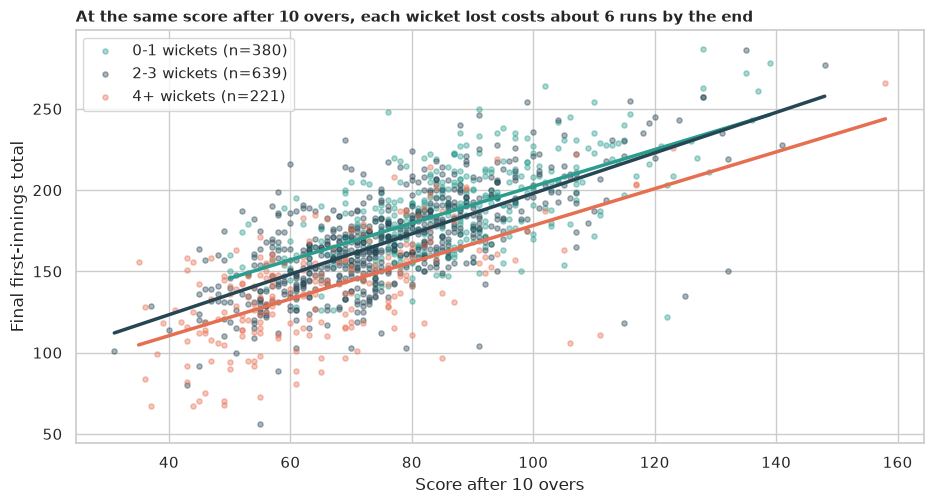

In [6]:
at_ten = snapshots[snapshots["overs_done"] == 10].copy()
design = sm.add_constant(at_ten[["score", "wkts"]])
resource_model = sm.OLS(at_ten["total"], design).fit(cov_type="HC3")
ci = resource_model.conf_int()
print(
    f"Innings analysed (state after 10 overs): {len(at_ten):,}   R-squared = "
    f"{resource_model.rsquared:.2f}"
)
for name, label in (("score", "each extra run already scored"), ("wkts", "each extra wicket lost")):
    print(
        f"Final-total change for {label}: {resource_model.params[name]:+.2f} runs "
        f"(95% CI {ci.loc[name, 0]:+.2f} to {ci.loc[name, 1]:+.2f}), "
        f"p = {resource_model.pvalues[name]:.1e}"
    )

bands = pd.cut(at_ten["wkts"], [-1, 1, 3, 10], labels=["0-1 wickets", "2-3 wickets", "4+ wickets"])
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for band, color in zip(bands.cat.categories, (TEAL, NAVY, ORANGE), strict=True):
    part = at_ten[bands == band]
    ax.scatter(
        part["score"], part["total"], s=14, alpha=0.4, color=color, label=f"{band} (n={len(part)})"
    )
    line = np.polyfit(part["score"], part["total"], 1)
    xs = np.linspace(part["score"].min(), part["score"].max(), 30)
    ax.plot(xs, np.polyval(line, xs), color=color, lw=2.5)
ax.set_xlabel("Score after 10 overs")
ax.set_ylabel("Final first-innings total")
ax.legend(loc="upper left")
cost = resource_model.params["wkts"]
ax.set_title(
    f"At the same score after 10 overs, each wicket lost costs about {abs(cost):.0f} runs "
    "by the end",
    loc="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "02_wickets_cost.png", dpi=150)
plt.show()

**How to read this.** After 10 overs the regression explains about **57%** of the variation in final totals. Each **extra run already scored** adds about **+1.14 runs** to the final total (the side keeps scoring and tends to accelerate at the end). But each **extra wicket lost** *lowers* the final total by about **6.5 runs at the same score** (95% CI −7.6 to −5.3, p ≈ 3e-28), so **we reject H₀**: wickets in hand are a real resource. In the plot, the three coloured lines are parallel-ish but the *more wickets lost* line (orange) sits below the others at any given score.

The same logic is what any good forecast has to capture: **score, wickets and recent form together, not just the run rate.**

## 8. H4: forecasting the final score, honestly

*What:* now the main task. At the end of over 6 (end of the powerplay), 10, 15 and 18, forecast the final first-innings total. The ladder of forecasters:

1. **"Par score":** always predict the average total of the previous two seasons (it adapts to the era; ignores the match state).
2. **Current run rate (CRR):** `score / balls × 120`. The commentator's projection.
3. **Linear model on the remaining runs:** predicts `final − score` from physically meaningful features: balls left × the current run rate, balls left × the recent (last 5 overs) rate, and balls left × wickets in hand. Fitted by ordinary least squares.
4. **Gradient boosting** (`HistGradientBoostingRegressor`) on the same features plus the batting team, bowling team, ground and `league_level`, which can learn interactions.

**How we avoid cheating (leakage).** With 19 snapshots per match and a game that drifts upward, a random split would put snapshots of the *same match* (or the *same season*) in both training and test sets. Instead we use **rolling-origin evaluation by season**: for each test season from 2018 to 2026, **train only on all earlier seasons**, then forecast that whole season. The `league_level` feature only uses earlier seasons. Models predict the *remaining runs* (so the forecast = score so far + predicted remaining).

**How we score.** **MAE (mean absolute error)** is the typical miss in runs (lower is better). Confidence intervals use a **cluster bootstrap**: re-draw whole *matches* with replacement 5,000 times.

In [7]:
def add_features(frame: pd.DataFrame) -> pd.DataFrame:
    """Adds physically meaningful features for forecasting the remaining runs.

    Args:
        frame: Snapshots from :func:`build_snapshots`.

    Returns:
        Copy of the table with balls left, the current run rate and recent-form features.
    """
    out = frame.copy()
    out["balls_left"] = BALLS_IN_INNINGS - out["balls"]
    out["crr"] = out["score"] / out["balls"]
    out["recent_rate"] = out["last5_runs"] / (np.minimum(out["overs_done"], 5) * 6)
    out["crr_x_left"] = out["crr"] * out["balls_left"]
    out["recent_x_left"] = out["recent_rate"] * out["balls_left"]
    out["wickets_in_hand_x_left"] = (10 - out["wkts"]) * out["balls_left"]
    out["remaining"] = out["total"] - out["score"]
    return out


LINEAR_FEATURES = ["crr_x_left", "recent_x_left", "wickets_in_hand_x_left", "balls_left"]
NUMERIC_FEATURES = [
    "score",
    "wkts",
    "balls",
    "last5_runs",
    "last5_wickets",
    "balls_left",
    "crr",
    "recent_rate",
    "crr_x_left",
    "recent_x_left",
    "wickets_in_hand_x_left",
]
CATEGORICAL_FEATURES = ["batting_team", "bowling_team", "ground"]


def fit_boosting(train: pd.DataFrame, columns: list[str], categorical: list[str]):
    """Fits gradient boosting on the remaining runs with native categorical support.

    Args:
        train: Training snapshots (with features added).
        columns: Feature columns to use.
        categorical: Which of those columns are categorical.

    Returns:
        A fitted model and the list of columns, so predictions can reuse the same order.
    """
    frame = train[columns].copy()
    for name in categorical:
        frame[name] = frame[name].astype("category")
    model = HistGradientBoostingRegressor(
        max_depth=4,
        learning_rate=0.05,
        max_iter=300,
        min_samples_leaf=40,
        l2_regularization=1.0,
        categorical_features="from_dtype",
        early_stopping=False,
        random_state=SEED,
    ).fit(frame, train["remaining"])
    return model, {name: frame[name].cat.categories for name in categorical}


def predict_boosting(
    model, categories: dict, frame: pd.DataFrame, columns: list[str]
) -> np.ndarray:
    """Predicts the remaining runs, mapping unseen category levels to missing.

    Args:
        model: Fitted boosting model.
        categories: Training categories per categorical column.
        frame: Snapshots to predict.
        columns: Feature columns, in training order.

    Returns:
        Predicted remaining runs.
    """
    data = frame[columns].copy()
    for name, levels in categories.items():
        known = data[name].where(data[name].isin(levels))
        data[name] = known.astype(pd.CategoricalDtype(levels))
    return model.predict(data)

In [8]:
all_features = add_features(snapshots)
MODEL_NAMES = [
    "Par score (last 2 seasons)",
    "Current run rate",
    "Linear (remaining runs)",
    "Boosting: all features",
    "Boosting: no team or ground",
    "Boosting: no league level",
]
test_seasons = [s for s in sorted(all_features["season"].unique()) if s >= FIRST_TEST_SEASON]

rows = []
for season in test_seasons:
    train = all_features[all_features["season"] < season]
    test = all_features[
        (all_features["season"] == season) & all_features["overs_done"].isin(CHECKPOINTS)
    ]
    linear = LinearRegression().fit(train[LINEAR_FEATURES], train["remaining"])
    full_cols = NUMERIC_FEATURES + CATEGORICAL_FEATURES + ["league_level"]
    no_names = NUMERIC_FEATURES + ["league_level"]
    no_level = NUMERIC_FEATURES + CATEGORICAL_FEATURES
    boost_all = fit_boosting(train, full_cols, CATEGORICAL_FEATURES)
    boost_plain = fit_boosting(train, no_names, [])
    boost_nolevel = fit_boosting(train, no_level, CATEGORICAL_FEATURES)

    predictions = {
        "Par score (last 2 seasons)": test["league_level"].to_numpy(),
        "Current run rate": (test["crr"] * BALLS_IN_INNINGS).to_numpy(),
        "Linear (remaining runs)": test["score"].to_numpy() + linear.predict(test[LINEAR_FEATURES]),
        "Boosting: all features": test["score"].to_numpy()
        + predict_boosting(*boost_all, test, full_cols),
        "Boosting: no team or ground": test["score"].to_numpy()
        + predict_boosting(*boost_plain, test, no_names),
        "Boosting: no league level": test["score"].to_numpy()
        + predict_boosting(*boost_nolevel, test, no_level),
    }
    block = test[["match_id", "season", "overs_done", "total"]].copy()
    for name, values in predictions.items():
        block[name] = values
    rows.append(block)

forecasts = pd.concat(rows, ignore_index=True)
errors = forecasts[MODEL_NAMES].sub(forecasts["total"], axis=0).abs()
errors = pd.concat([forecasts[["match_id", "season", "overs_done"]], errors], axis=1)
errors = errors.dropna()
n_matches = errors["match_id"].nunique()
print(
    f"Test seasons {test_seasons[0]} to {test_seasons[-1]}: {n_matches} matches, "
    f"{len(errors):,} forecasts scored"
)
mae = errors.groupby("overs_done")[MODEL_NAMES].mean().loc[CHECKPOINTS].T
mae.columns = [f"after over {k}" for k in CHECKPOINTS]
mae.round(1)

Test seasons 2018 to 2026: 605 matches, 2,406 forecasts scored


,after over 6,after over 10,after over 15,after over 18
Par score (last 2 seasons),26.6,26.6,26.4,25.8
Current run rate,29.9,22.6,14.9,8.5
Linear (remaining runs),21.6,19.5,12.0,8.1
Boosting: all features,22.5,18.8,12.1,8.5
Boosting: no team or ground,21.4,17.9,11.1,7.4
Boosting: no league level,23.0,18.8,12.1,8.1


**How to read this.** (The numbers are the typical miss in runs; lower is better. Each column is the moment of the forecast.)

- **Par score** (ignore the match, just quote the recent average) misses by about **26 to 27 runs** at every checkpoint: the bar to beat.
- **Current run rate** is poor early (a miss of about **30 runs after over 6**, worse than the par score) because early overs are slow compared with the finish, but it **improves quickly**: 22.6 after over 10, 14.9 after over 15 and 8.5 after over 18.
- **The linear model** (balls left × the run rate, recent form and wickets in hand) is **much better early** (about **21.6** after over 6 against 29.9 for CRR) and still ahead at over 15 (12.0 against 14.9).
- **Boosting with all features** is similar to the linear model (22.5, 18.8, 12.1 and 8.5), and **boosting without team and ground names is the best of all**: about **21.4, 17.9, 11.1 and 7.4 runs** at the four checkpoints.
- All forecasts get better as the innings progresses: after 18 overs only 12 balls remain, so there is little left to predict.

Are the gaps real, or just noise? Next the cluster-bootstrap CIs and paired comparisons.

In [9]:
def cluster_bootstrap(
    errors_a: pd.Series, errors_b: pd.Series | None, rng: np.random.Generator
) -> tuple[float, float, float]:
    """Cluster-bootstrap 95% CI for a mean error (or a difference of mean errors), by match.

    Args:
        errors_a: Absolute errors of model A, one value per match (index = match).
        errors_b: Absolute errors of model B on the same matches, or None for a plain MAE.
        rng: Random generator.

    Returns:
        Observed value, CI lower bound, CI upper bound.
    """
    values = (errors_a - errors_b if errors_b is not None else errors_a).to_numpy()
    picks = rng.integers(0, len(values), (N_BOOTSTRAP, len(values)))
    boot = values[picks].mean(axis=1)
    lo, hi = np.percentile(boot, [2.5, 97.5])
    return float(values.mean()), float(lo), float(hi)


rng = np.random.default_rng(SEED)
per_checkpoint = {
    k: errors[errors["overs_done"] == k].set_index("match_id")[MODEL_NAMES] for k in CHECKPOINTS
}
rows = {}
for k, frame in per_checkpoint.items():
    for name in MODEL_NAMES:
        mean, lo, hi = cluster_bootstrap(frame[name], None, rng)
        rows[(k, name)] = {"MAE": mean, "ci_low": lo, "ci_high": hi}
mae_ci = pd.DataFrame(rows).T
mae_ci.index.names = ["overs", "model"]

diff_rows = {}
for k, frame in per_checkpoint.items():
    for name in MODEL_NAMES:
        if name == "Current run rate":
            continue
        d, lo, hi = cluster_bootstrap(frame[name], frame["Current run rate"], rng)
        diff_rows[(k, name)] = {"MAE minus CRR": d, "ci_low": lo, "ci_high": hi}
vs_crr = pd.DataFrame(diff_rows).T
vs_crr.index.names = ["overs", "model"]
vs_crr.loc[(slice(None), ["Linear (remaining runs)", "Boosting: all features"]), :].round(2)

,,MAE minus CRR,ci_low,ci_high
overs,model,,,
6,Linear (remaining runs),-8.23,-9.94,-6.54
10,Linear (remaining runs),-3.14,-4.17,-2.07
15,Linear (remaining runs),-2.91,-3.48,-2.31
18,Linear (remaining runs),-0.42,-1.08,0.26
6,Boosting: all features,-7.34,-9.25,-5.41
10,Boosting: all features,-3.86,-5.19,-2.48
15,Boosting: all features,-2.80,-3.67,-1.93
18,Boosting: all features,-0.03,-0.61,0.54


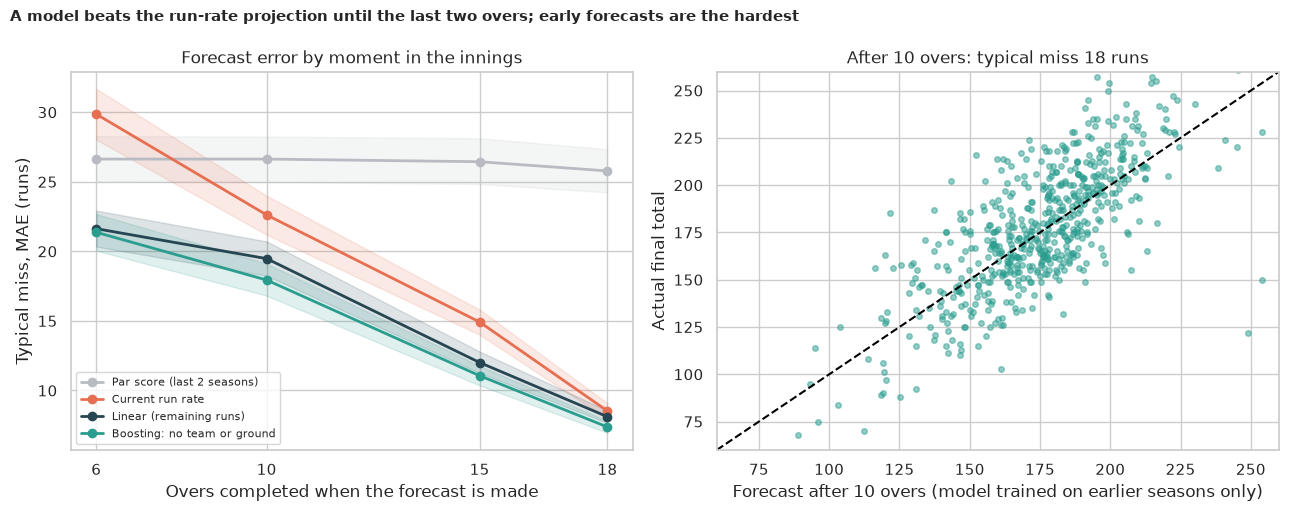

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
palette = {
    "Par score (last 2 seasons)": GREY,
    "Current run rate": ORANGE,
    "Linear (remaining runs)": NAVY,
    "Boosting: no team or ground": TEAL,
}
for name, color in palette.items():
    part = mae_ci.xs(name, level="model")
    axes[0].plot(part.index, part["MAE"], marker="o", color=color, lw=2, label=name)
    axes[0].fill_between(part.index, part["ci_low"], part["ci_high"], color=color, alpha=0.15)
axes[0].set_xlabel("Overs completed when the forecast is made")
axes[0].set_ylabel("Typical miss, MAE (runs)")
axes[0].set_xticks(CHECKPOINTS)
axes[0].legend(fontsize=8)
axes[0].set_title("Forecast error by moment in the innings")

focus = forecasts[forecasts["overs_done"] == 10]
best = "Boosting: no team or ground"
axes[1].scatter(focus[best], focus["total"], s=16, alpha=0.5, color=TEAL)
limits = [60, 260]
axes[1].plot(limits, limits, color="black", ls="--")
axes[1].set_xlim(*limits)
axes[1].set_ylim(*limits)
axes[1].set_xlabel("Forecast after 10 overs (model trained on earlier seasons only)")
axes[1].set_ylabel("Actual final total")
axes[1].set_title(f"After 10 overs: typical miss {mae.loc[best, 'after over 10']:.0f} runs")
fig.suptitle(
    "A model beats the run-rate projection until the last two overs; early forecasts "
    "are the hardest",
    x=0.01,
    ha="left",
    fontweight="bold",
    fontsize=11,
)
fig.tight_layout()
fig.savefig(OUT_DIR / "03_forecast_error.png", dpi=150)
plt.show()

**How to read this.** The table shows the **difference in MAE versus the current-run-rate forecast** with a 95% cluster-bootstrap CI (a negative number means *better than CRR*). Both the linear model and boosting are **clearly better than the run-rate projection after overs 6, 10 and 15** (negative differences with CIs that exclude 0): about **−8 runs** (linear, CI −9.9 to −6.5) and **−7 runs** (boosting) after over 6, about **−3 to −4 runs** after over 10 and about **−3 runs** after over 15. **By over 18 the advantage is gone** (−0.4 and −0.0, CIs including 0): with 12 balls left, the run rate is as good as anything. **We reject H₀ for the first three checkpoints and fail to reject it at over 18.** A model beats the commentator's projection mostly *early* in the innings.

Left chart: the orange CRR line starts far above the others and falls steeply; the grey par-score line is flat at about 27 runs; the teal boosting line is below CRR until over 18, where the two meet. Right chart: forecasts made after 10 overs against the actual totals: they follow the diagonal but with substantial scatter, because 10 overs (60 balls) is a long way left to bat.

## 9. H5: do team and ground names help?

*What:* it feels obvious that the batting team and the ground matter (some grounds are small and high-scoring). We test it by **removing** those names from the boosting model, and separately removing the `league_level` (the recent average total). **H₀:** removing them changes nothing. The comparison is **paired** on the same matches with a cluster bootstrap.

In [11]:
ablation = {}
rng = np.random.default_rng(SEED + 1)
for k, frame in per_checkpoint.items():
    for name in ("Boosting: no team or ground", "Boosting: no league level"):
        d, lo, hi = cluster_bootstrap(frame[name], frame["Boosting: all features"], rng)
        ablation[(k, name)] = {"MAE change vs full model": d, "ci_low": lo, "ci_high": hi}
ablation = pd.DataFrame(ablation).T
ablation.index.names = ["overs", "model without..."]
ablation["CI excludes 0?"] = (ablation["ci_low"] > 0) | (ablation["ci_high"] < 0)
ablation.round(2)

MAE change vs full model  ci_low  ci_high  \
overs model without...                                                         
6     Boosting: no team or ground                     -1.15   -2.03    -0.28   
      Boosting: no league level                        0.46   -0.18     1.07   
10    Boosting: no team or ground                     -0.81   -1.52    -0.11   
      Boosting: no league level                        0.06   -0.44     0.56   
15    Boosting: no team or ground                     -1.06   -1.55    -0.56   
      Boosting: no league level                       -0.05   -0.39     0.29   
18    Boosting: no team or ground                     -1.12   -1.52    -0.71   
      Boosting: no league level                       -0.35   -0.65    -0.06   

                                   CI excludes 0?  
overs model without...                             
6     Boosting: no team or ground            True  
      Boosting: no league level             False  
10    Boosting: no team or ground            True  
      Boosting: no league level             False  
15    Boosting: no team or ground            True  
      Boosting: no league level             False  
18    Boosting: no team or ground            True  
      Boosting: no league level              True

**How to read this.** (A positive number means removing the ingredient made forecasts *worse*; a negative number means *better*.)

- **Removing team and ground names makes forecasts *better*, not worse**: the error falls by about **0.8 to 1.2 runs at every checkpoint**, and all four CIs exclude 0. **We reject H₀, but in the surprising direction: the names add noise, not signal.** With about 15 teams and 42 grounds spread over a modest number of matches (and teams changing over the years), the model overfits the identities, while the state of the innings (score, wickets, recent form) already carries what matters. (A cautionary tale about adding features because they "feel" relevant.)
- **Removing the `league_level`** (the previous two seasons' average total) changes the error by **less than half a run** at every checkpoint, and the CIs include 0 except at over 18 (where removing it *helps* by 0.35 runs): **we fail to reject H₀**. The recent-form features already track how fast the innings is going, so a separate "era" number adds nothing detectable.

The lesson: **good features about the *state of the game* beat clever features about *identity* or *era*.**

## 10. H6: how wide should the "likely range" be?

*What:* a forecast of "170" is more useful as "170, likely between 150 and 190". We build an **80% interval** from the **errors of earlier test seasons** at the same checkpoint (the 10th and 90th percentiles of the signed error "actual minus forecast"), and then see how often the actual total lands inside for the *next* season. This is honest: each season's interval is built only from seasons that came before it. **H₀:** the coverage is 80%. We test it with a binomial test and a Wilson CI.

In [12]:
boost = forecasts[["match_id", "season", "overs_done", "total", "Boosting: all features"]].dropna()
boost = boost.assign(error=boost["total"] - boost["Boosting: all features"])
hits = []
for season in [s for s in test_seasons if s > FIRST_TEST_SEASON]:
    past = boost[boost["season"] < season]
    now = boost[boost["season"] == season]
    for k in CHECKPOINTS:
        lo, hi = np.percentile(past.loc[past["overs_done"] == k, "error"], [10, 90])
        errs = now.loc[now["overs_done"] == k, "error"]
        hits.append(
            pd.DataFrame(
                {"overs": k, "season": season, "inside": errs.between(lo, hi), "width": hi - lo}
            )
        )
hits = pd.concat(hits)

summary = hits.groupby("overs").agg(
    forecasts=("inside", "size"), covered=("inside", "sum"), width=("width", "mean")
)
summary["coverage"] = summary["covered"] / summary["forecasts"]
bounds = [
    proportion_confint(c, n, method="wilson")
    for c, n in zip(summary["covered"], summary["forecasts"], strict=True)
]
summary["ci_low"] = [b[0] for b in bounds]
summary["ci_high"] = [b[1] for b in bounds]
summary["binomial p"] = [
    stats.binomtest(int(c), int(n), 0.8).pvalue
    for c, n in zip(summary["covered"], summary["forecasts"], strict=True)
]
overall = hits["inside"].mean()
print(
    f"Overall coverage of the nominal 80% interval: {overall:.1%} "
    f"({int(hits['inside'].sum())} of {len(hits)})"
)
summary[["forecasts", "coverage", "ci_low", "ci_high", "binomial p", "width"]].style.format(
    {
        "coverage": "{:.1%}",
        "ci_low": "{:.1%}",
        "ci_high": "{:.1%}",
        "binomial p": "{:.2f}",
        "width": "{:.0f} runs",
    }
)

Overall coverage of the nominal 80% interval: 79.4% (1720 of 2167)


,forecasts,coverage,ci_low,ci_high,binomial p,width
overs,,,,,,
6,545,76.7%,73.0%,80.1%,0.06,67 runs
10,545,81.1%,77.6%,84.2%,0.56,61 runs
15,542,80.8%,77.3%,83.9%,0.67,41 runs
18,535,78.9%,75.2%,82.1%,0.52,27 runs


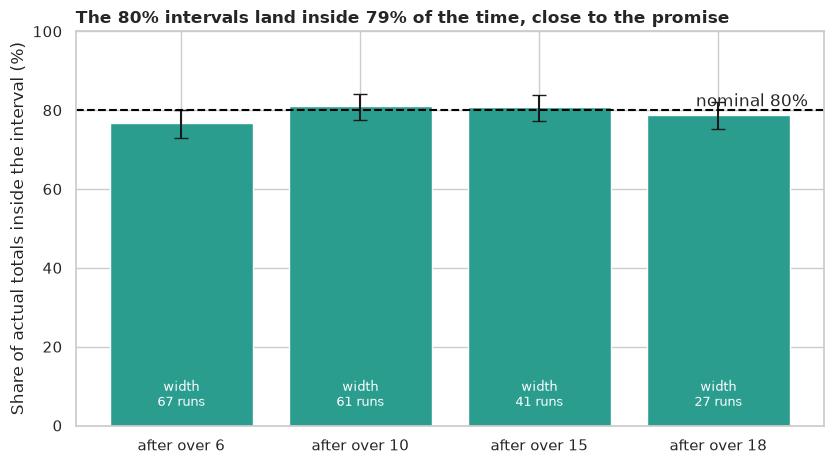

In [13]:
fig, ax = plt.subplots(figsize=(8.5, 4.8))
x = np.arange(len(summary))
ax.bar(
    x,
    summary["coverage"] * 100,
    color=TEAL,
    yerr=[
        (summary["coverage"] - summary["ci_low"]) * 100,
        (summary["ci_high"] - summary["coverage"]) * 100,
    ],
    capsize=5,
)
ax.axhline(80, color="black", ls="--")
ax.text(len(summary) - 0.5, 81, "nominal 80%", ha="right")
for i, width in enumerate(summary["width"]):
    ax.text(i, 5, f"width\n{width:.0f} runs", ha="center", color="white", fontsize=9)
ax.set_xticks(x, [f"after over {k}" for k in summary.index])
ax.set_ylabel("Share of actual totals inside the interval (%)")
ax.set_ylim(0, 100)
ax.set_title(
    f"The 80% intervals land inside {overall:.0%} of the time, close to the promise",
    loc="left",
    fontweight="bold",
)
fig.tight_layout()
fig.savefig(OUT_DIR / "04_interval_coverage.png", dpi=150)
plt.show()

**How to read this.** Intervals built from *earlier seasons' errors* land inside the actual total **79.4% of the time overall** (1,720 of 2,167), very close to the promised 80%. By checkpoint: **76.7% after over 6** (CI 73.0% to 80.1%, p ≈ 0.06, borderline), **81.1% after over 10**, **80.8% after over 15** and **78.9% after over 18** (all with p > 0.5). **We fail to reject H₀ at every checkpoint**: the intervals are about as honest as promised (slightly too narrow right after over 6). They also shrink as the innings goes on: **about 67 runs wide after over 6, 61 after over 10, 41 after over 15 and 27 after over 18**, the quantified version of "the closer to the end, the surer we are". Note how wide the early ranges are: after 6 overs the innings is *genuinely* uncertain by about ±30 runs.

## 11. 🎯 Takeaways

1. **The legacy notebook predicted the wrong thing.** `total_runs` in a ball-by-ball file is the runs from *one ball*, and the model used post-match columns (`winner`, `result`). We rebuilt the task as forecasting the **first-innings final total** from the state of the innings.
2. **The game keeps changing.** First-innings totals average about 189 in 2023 to 2026 against about 162 earlier (Theil-Sen slope about +1.9 runs per season; Cliff's δ ≈ +0.43). Forecasts must be tested by training on the past and predicting the future.
3. **Wickets in hand are a resource.** At the same score after 10 overs, each wicket lost costs about 6.5 runs by the end (95% CI −7.6 to −5.3).
4. **Beating the commentator's projection is easy early and hard late.** A model beats the current run rate by about 7 to 8 runs after over 6, 3 to 4 after over 10, 3 after over 15 and not at all after over 18. Typical misses fall from about 21 runs (over 6) to about 7 (over 18).
5. **The state of the game beats identity.** Removing team and ground names *improves* forecasts by about 1 run (the names overfit), and the recent-seasons level feature adds nothing detectable.
6. **Honest ranges are available.** Intervals calibrated on earlier seasons cover 79.4% of the time (target 80%), and widen from about 27 runs late in the innings to about 67 after over 6.
7. **Batting second helps a bit; the toss does not.** Chasing sides win 54.7% of decided matches (p ≈ 0.001); the toss winner wins 51.6% (p ≈ 0.29).

## 12. ⚠️ Limitations and edge cases

- **First innings only.** The second innings is a chase with a target, which changes how teams bat; this notebook does not model it.
- **Era drift is only partly handled.** The `league_level` feature (the previous two seasons' average) helps, but a sudden rule change (such as the "impact player" substitute from 2023) could still shift scoring faster than the feature adapts.
- **No player information.** We know nothing about *who* is batting or bowling, which obviously matters (a star batter at the crease is not the same as a tail-ender). Adding batter-level strength would be the natural next step.
- **Rain and short innings.** A few innings were cut short; they are kept (the total is what it is) but are unusual.
- **Intervals are calibrated on earlier test seasons only**, so the first test season has no interval and the early ones rest on few matches.
- **Association, not cause.** "A wicket costs 6 runs" is a statistical regularity at a given score, not a promise about any particular match.
- **Cluster bootstrap and single test fold structure.** Rolling-origin evaluation gives nine test seasons (about 600 matches). Results for one season can be noisy, and the exact numbers will move as new seasons arrive.
- **Modest tuning.** Boosting uses sensible fixed settings without a full hyper-parameter search.

---
*Run `uv run jupyter nbconvert --to html --execute ML/ipl-score-prediction/ipl_score_prediction.ipynb --output-dir docs --output ml-ipl-score-prediction` to rebuild the web version (`docs/ml-ipl-score-prediction.html`).*